# 하이퍼파라미터 튜닝 및 모델 성능 비교
**Baseline과 클래스 불균형 처리 결과를 바탕으로, 주요 후보 모델의 하이퍼파라미터와 불균형 처리 방법을 Train 내부 CV로 함께 튜닝하고 동일한 기준으로 비교합니다.**

| 항목 | 설정 |
|---|---|
| 후보 모델 | LightGBM, XGBoost, GBM, Random Forest (Baseline·불균형 처리에서 상위 4개) + 튜닝된 모델들의 Soft Voting 앙상블 |
| 탐색 방법 | `RandomizedSearchCV` — 불균형 처리 방법(샘플러·가중치)도 탐색 공간에 포함 |
| 검증 | 팀 공통 `StratifiedKFold(5, shuffle=True, random_state=42)`, scoring = `f1_macro` |
| 재확인 | 선택된 설정을 **반복 층화 CV(5×3)** 로 다시 평가 (탐색에 쓴 fold에 맞춰진 낙관적 점수 보정) |
| 누수 방지 | 전처리·샘플링·가중치 계산이 모두 Pipeline/래퍼 안에서 **Training fold로만** 수행 |
| Test 사용 | **사용하지 않음** — 최종 모델 선정 후 최종 평가에서 1회만 사용 |
| 목표 | Macro F1 ≥ 0.83 |

> **실행 시간**: 탐색·평가를 CPU 코어 수만큼 병렬 실행합니다. 처음 실행 시 2코어 기준 약 약 25분(탐색 약 15분 + 평가 약 8분)이 걸리며 코어가 많을수록 빨라집니다.
> 결과는 `results/tuning/Taegyeom_tuning_cache.pkl`에 저장되어, 이후에는 `RERUN = False`(기본값)로 **수 초 안에** 결과를 다시 볼 수 있습니다.

In [1]:
import sys, warnings, pickle, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import loguniform, randint, uniform

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore")

from config import RANDOM_STATE, CV
from load_data import load_data
from Taegyeom_model_utils import (CLASS_ORDER, MINORITY_CLASSES, make_pipeline, make_sampling_pipeline, discrete_indices,
                                  LabelEncodedClassifier, BalancedWeightClassifier, over_strategy, run_many,
                                  summarize_runs, per_class_report, confusion_df, key_error_counts)

from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTENC

RESULT_DIR = PROJECT_ROOT / "results" / "tuning"; RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 60)

RERUN = False                                     # True: 탐색·평가 다시 실행 / False: 저장된 결과가 있으면 불러오기
CACHE = RESULT_DIR / "Taegyeom_tuning_cache.pkl"
cache = pickle.load(open(CACHE, "rb")) if (CACHE.exists() and not RERUN) else {}
def cached(key, fn):
    if key not in cache:
        cache[key] = fn(); pickle.dump(cache, open(CACHE, "wb"))
    return cache[key]

# ---- 시각화 공통 스타일 ----
BLUE, BLUE_LIGHT, ORANGE, AQUA, RED, GRAY_MID = "#2a78d6", "#86b6ef", "#eb6834", "#1baf7a", "#e34948", "#f0efec"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams.update({
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
})
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [RED, GRAY_MID, BLUE])
def save(fig, name): fig.savefig(FIG_DIR / name); plt.show()

## 1. 데이터 불러오기 및 이전 단계 결과

In [2]:
X_train, X_test, y_train, y_test = load_data()   # X_test / y_test는 사용하지 않음
FEATURES = list(X_train.columns); CAT_IDX = discrete_indices(FEATURES)
print("X_train:", X_train.shape)

base = pd.read_csv(PROJECT_ROOT / "results/baseline/Taegyeom_baseline_cv_summary.csv", index_col=0)
imb = pd.read_csv(PROJECT_ROOT / "results/imbalance/Taegyeom_imbalance_cv_summary.csv", keep_default_na=False).set_index(["model", "method"])
prev = pd.DataFrame({
    "Baseline Macro F1": base["macro_f1_mean"],
    "불균형 처리 최선": [imb.loc[m].drop(index=["None", "SMOTE IR=1"])["macro_f1_mean"].idxmax() for m in base.index],
    "불균형 처리 후 Macro F1": [imb.loc[m].drop(index=["None", "SMOTE IR=1"])["macro_f1_mean"].max() for m in base.index],
    "Train Macro F1 (Baseline)": base["train_macro_f1"],
}).round(4)
prev

X_train: (1552, 26)


,Baseline Macro F1,불균형 처리 최선,불균형 처리 후 Macro F1,Train Macro F1 (Baseline)
model,,,,
Logistic Regression,0.7191,SMOTENC IR≤3.5,0.7221,0.7488
Decision Tree,0.7207,SMOTENC IR≤7,0.7385,1.0000
Random Forest,0.7899,SMOTENC IR=1,0.7955,1.0000
GBM,0.7958,CW α=1,0.8095,0.9897
XGBoost,0.8109,SMOTENC IR=1,0.8201,1.0000
LightGBM,0.8044,SMOTENC IR=1,0.8268,1.0000


**튜닝 방향**
- 상위 앙상블 모델은 모두 **Train Macro F1 ≈ 1.0**으로 학습 데이터를 외우고 있습니다(Validation과 약 0.19~0.21 차이).
  → 트리 크기·잎 노드 최소 표본·학습률·행/열 샘플링·정규화를 조정해 **과적합을 줄이는 방향**으로 탐색합니다.
- 클래스 불균형 처리의 효과가 모델마다 달랐으므로(LightGBM·RF는 SMOTENC, GBM은 가중치, XGBoost는 효과 불분명) **처리 방법도 탐색 공간에 포함**합니다.
  - 샘플러: SMOTENC 균등화 / 사용 안 함(`passthrough`)
  - 가중치: LightGBM·RF는 `class_weight`, GBM·XGBoost는 `BalancedWeightClassifier`의 `alpha` (fit 시점의 Training fold로 가중치 계산)

## 2. 탐색 공간

In [3]:
RS = RANDOM_STATE
smotenc = lambda: SMOTENC(categorical_features=CAT_IDX, sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RS)
XP = "model__estimator__estimator__"          # BalancedWeightClassifier → LabelEncodedClassifier → XGBClassifier
GP = "model__estimator__"                     # BalancedWeightClassifier → GradientBoostingClassifier

SEARCH = {
    "LightGBM": dict(
        pipe=make_sampling_pipeline(LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1, subsample_freq=1), FEATURES, smotenc()),
        space={"sampler": [smotenc(), "passthrough"], "model__class_weight": [None, "balanced"],
               "model__n_estimators": randint(150, 900), "model__learning_rate": loguniform(0.01, 0.15),
               "model__num_leaves": randint(8, 64), "model__max_depth": [-1, 4, 6, 8, 10],
               "model__min_child_samples": randint(5, 40), "model__subsample": uniform(0.6, 0.4),
               "model__colsample_bytree": uniform(0.4, 0.6), "model__reg_lambda": loguniform(1e-3, 10)},
        n_iter=30),
    "XGBoost": dict(
        pipe=make_sampling_pipeline(BalancedWeightClassifier(LabelEncodedClassifier(XGBClassifier(random_state=RS, n_jobs=1)), alpha=0),
                                    FEATURES, smotenc()),
        space={"sampler": [smotenc(), "passthrough"], "model__alpha": [0, 0.5, 1],
               XP + "n_estimators": randint(150, 900), XP + "learning_rate": loguniform(0.01, 0.15), XP + "max_depth": randint(3, 9),
               XP + "min_child_weight": randint(1, 8), XP + "subsample": uniform(0.6, 0.4), XP + "colsample_bytree": uniform(0.4, 0.6),
               XP + "reg_lambda": loguniform(1e-2, 10), XP + "gamma": loguniform(1e-3, 1)},
        n_iter=25),
    "GBM": dict(
        pipe=make_pipeline(BalancedWeightClassifier(GradientBoostingClassifier(random_state=RS), alpha=1), FEATURES),
        space={"model__alpha": [0.5, 1], GP + "n_estimators": randint(100, 400), GP + "learning_rate": loguniform(0.03, 0.2),
               GP + "max_depth": randint(2, 6), GP + "subsample": uniform(0.6, 0.4), GP + "max_features": [None, "sqrt", 0.5],
               GP + "min_samples_leaf": randint(1, 10)},
        n_iter=10),
    "Random Forest": dict(
        pipe=make_sampling_pipeline(RandomForestClassifier(random_state=RS, n_jobs=1), FEATURES, smotenc()),
        space={"sampler": [smotenc(), "passthrough"], "model__class_weight": [None, "balanced_subsample"],
               "model__n_estimators": randint(200, 600), "model__max_depth": [None, 10, 15, 20],
               "model__min_samples_leaf": randint(1, 6), "model__max_features": ["sqrt", 0.3, 0.5]},
        n_iter=12),
}
pd.DataFrame({m: {"탐색 횟수": v["n_iter"], "학습 횟수(×5 fold)": v["n_iter"] * 5,
                  "탐색 파라미터": ", ".join(k.split("__")[-1] for k in v["space"])} for m, v in SEARCH.items()}).T

,탐색 횟수,학습 횟수(×5 fold),탐색 파라미터
LightGBM,30,150,"sampler, class_weight, n_estimators, learning_rate, num_..."
XGBoost,25,125,"sampler, alpha, n_estimators, learning_rate, max_depth, ..."
GBM,10,50,"alpha, n_estimators, learning_rate, max_depth, subsample..."
Random Forest,12,60,"sampler, class_weight, n_estimators, max_depth, min_samp..."


## 3. RandomizedSearchCV 실행

In [4]:
def do_search(name):
    s = SEARCH[name]
    rs = RandomizedSearchCV(s["pipe"], s["space"], n_iter=s["n_iter"], scoring="f1_macro", cv=CV, n_jobs=-1,
                            random_state=RS, return_train_score=True, refit=False)
    t0 = time.perf_counter(); rs.fit(X_train, y_train)
    res = pd.DataFrame(rs.cv_results_)
    res["search_sec"] = time.perf_counter() - t0
    return res

searches, t_all = {}, time.perf_counter()
for name in SEARCH:
    searches[name] = cached(("search", name), lambda n=name: do_search(n))
    r = searches[name]; b = r.loc[r["rank_test_score"].idxmin()]
    print(f"{name:14s} 최고 CV Macro F1 {b['mean_test_score']:.4f} ± {b['std_test_score']:.4f}  "
          f"(Train {b['mean_train_score']:.4f}, 탐색 {r['search_sec'].iloc[0]:.0f}초)")
print(f"\n소요 {time.perf_counter() - t_all:.0f}초")

LightGBM       최고 CV Macro F1 0.8298 ± 0.0183  (Train 1.0000, 탐색 336초)
XGBoost        최고 CV Macro F1 0.8226 ± 0.0230  (Train 0.9992, 탐색 237초)
GBM            최고 CV Macro F1 0.8225 ± 0.0182  (Train 0.9976, 탐색 153초)
Random Forest  최고 CV Macro F1 0.7948 ± 0.0174  (Train 0.9752, 탐색 174초)

소요 0초


In [5]:
def clean(p):
    out = {}
    for k, v in p.items():
        k2 = k.split("__")[-1]
        if k2 == "sampler": v = "SMOTENC IR=1" if not isinstance(v, str) else "없음"
        elif isinstance(v, float): v = round(v, 4)
        out[k2] = v
    return out

best_params, rows = {}, []
for name, r in searches.items():
    top = r.sort_values("rank_test_score").head(5)
    best_params[name] = top.iloc[0]["params"]
    for rank, (_, row) in enumerate(top.iterrows(), 1):
        rows.append({"model": name, "순위": rank, "CV Macro F1": round(row["mean_test_score"], 4), "std": round(row["std_test_score"], 4),
                     "Train Macro F1": round(row["mean_train_score"], 4), **clean(row["params"])})
top_tbl = pd.DataFrame(rows).set_index(["model", "순위"])
top_tbl.to_csv(RESULT_DIR / "Taegyeom_tuning_search_top5.csv")
pd.concat({n: r for n, r in searches.items()}).drop(columns=["params"]).to_csv(RESULT_DIR / "Taegyeom_tuning_search_all.csv")
json.dump({n: clean(p) for n, p in best_params.items()}, open(RESULT_DIR / "Taegyeom_tuning_best_params.json", "w"), ensure_ascii=False, indent=2, default=str)
top_tbl

CV Macro F1     std  Train Macro F1        class_weight  colsample_bytree  learning_rate  max_depth  min_child_samples  n_estimators  num_leaves  reg_lambda  subsample       sampler  alpha   gamma  \
model         순위                                                                                                                                                                                                         
LightGBM      1        0.8298  0.0183          1.0000                 NaN            0.8779         0.0164       10.0               25.0           764        26.0      0.0025     0.7837  SMOTENC IR=1    NaN     NaN   
              2        0.8266  0.0168          1.0000            balanced            0.5416         0.0200        6.0               13.0           356        22.0      0.0028     0.7757  SMOTENC IR=1    NaN     NaN   
              3        0.8229  0.0095          1.0000            balanced            0.4221         0.0521        4.0               32.0           715        30.0      0.0130     0.9633  SMOTENC IR=1    NaN     NaN   
              4        0.8228  0.0208          1.0000                 NaN            0.7906         0.1191       -1.0               12.0           182        55.0      0.0304     0.8675  SMOTENC IR=1    NaN     NaN   
              5        0.8222  0.0170          1.0000                 NaN            0.9375         0.0362       10.0               36.0           883        44.0      0.0099     0.7642  SMOTENC IR=1    NaN     NaN   
XGBoost       1        0.8226  0.0230          0.9992                 NaN            0.8741         0.1229        4.0                NaN           177         NaN      3.8843     0.8493            없음    1.0  0.0657   
              2        0.8222  0.0260          1.0000                 NaN            0.5452         0.0787        5.0                NaN           443         NaN      0.1269     0.8529            없음    0.5  0.1039   
              3        0.8153  0.0132          0.9970                 NaN            0.5210         0.0362        7.0                NaN           883         NaN      0.0262     0.8418  SMOTENC IR=1    0.0  0.4867   
              4        0.8149  0.0140          0.9854                 NaN            0.4080         0.0460        4.0                NaN           495         NaN      0.0196     0.8737  SMOTENC IR=1    1.0  0.6708   
              5        0.8147  0.0212          1.0000                 NaN            0.7280         0.1381        4.0                NaN           311         NaN      0.1533     0.9707  SMOTENC IR=1    0.5  0.0036   
GBM           1        0.8225  0.0182          0.9976                 NaN               NaN         0.0691        4.0                NaN           134         NaN         NaN     0.9637           NaN    1.0     NaN   
              2        0.8213  0.0139          0.9958                 NaN               NaN         0.0424        5.0                NaN           153         NaN         NaN     0.8187           NaN    1.0     NaN   
              3        0.8203  0.0100          0.9570                 NaN               NaN         0.0318        3.0                NaN           301         NaN         NaN     0.9579           NaN    1.0     NaN   
              4        0.8192  0.0128          0.9887                 NaN               NaN         0.0403        4.0                NaN           199         NaN         NaN     0.6571           NaN    1.0     NaN   
              5        0.8161  0.0123          0.9981                 NaN               NaN         0.0328        4.0                NaN           266         NaN         NaN     0.6053           NaN    0.5     NaN   
Random Forest 1        0.7948  0.0174          0.9752  balanced_subsample               NaN            NaN       20.0                NaN           506         NaN         NaN        NaN  SMOTENC IR=1    NaN     NaN   
              2        0.7922  0.0158          0.9688                 NaN               NaN   

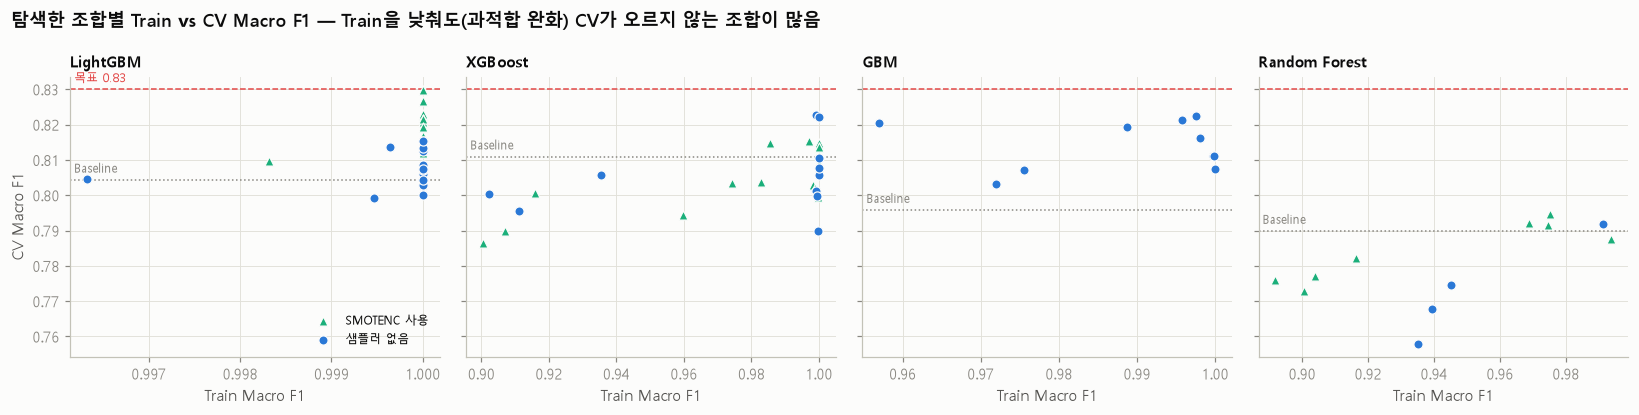

In [6]:
# 탐색 결과 분포: 각 점 = 하나의 하이퍼파라미터 조합. 샘플러 사용 여부로 구분
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, (name, r) in zip(axes, searches.items()):
    if "param_sampler" in r:
        use = r["param_sampler"].apply(lambda v: not isinstance(v, str))
    else:
        use = pd.Series(False, index=r.index)
    for flag, c, mk, lab in [(True, AQUA, "^", "SMOTENC 사용"), (False, BLUE, "o", "샘플러 없음")]:
        sub = r[use == flag]
        ax.scatter(sub["mean_train_score"], sub["mean_test_score"], s=36, color=c, marker=mk, edgecolor=SURFACE, lw=0.8, label=lab, zorder=3)
    base_f1 = base.loc[name, "macro_f1_mean"]
    ax.axhline(base_f1, color=MUTED, lw=1, ls=":"); ax.text(ax.get_xlim()[0], base_f1 + 0.002, " Baseline", color=MUTED, fontsize=8)
    ax.axhline(0.83, color=RED, lw=1, ls="--")
    ax.set_title(name, fontsize=10); ax.set_xlabel("Train Macro F1")
axes[0].set_ylabel("CV Macro F1"); axes[0].text(axes[0].get_xlim()[0], 0.832, " 목표 0.83", color=RED, fontsize=8)
axes[0].legend(loc="lower right", frameon=False, fontsize=8)
fig.suptitle("탐색한 조합별 Train vs CV Macro F1 — Train을 낮춰도(과적합 완화) CV가 오르지 않는 조합이 많음",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_tuning_search_scatter.png")

**해석 — 탐색 결과**
- **LightGBM 최고 0.830 ± 0.018**: 상위 5개 조합이 **모두 SMOTENC 균등화**를 선택했습니다(클래스 불균형 처리 실험 결과와 일치).
  최적 설정은 작은 학습률(0.016)에 많은 트리(764개), 잎 26개·깊이 10, 잎 최소 표본 25, 행 78%·열 88% 샘플링입니다.
- **XGBoost 최고 0.823 ± 0.023**: 상위 2개가 **샘플러 없음 + 클래스 가중치(α=1 / 0.5)** 였습니다. 불균형 처리 실험에서 XGBoost의 SMOTENC 효과가 불안정했던 것과 같은 결론입니다.
  얕은 트리(깊이 4)·177개·L2 정규화(3.9)로 비교적 단순한 모델이 선택되었습니다.
- **GBM 최고 0.823 ± 0.018**: 가중치 α=1, 깊이 4, 학습률 0.069, 트리 134개. Baseline(0.796) 대비 **+0.026으로 튜닝 효과가 가장 큰 모델**입니다(기본 깊이 3 → 4, 행 샘플링 96%).
- **Random Forest 최고 0.795**: Baseline 대비 +0.005로 튜닝 효과가 거의 없어 이후 후보에서 제외합니다.
- **과적합 관점**: 상위 조합의 Train Macro F1은 여전히 0.998~1.0입니다. 정규화를 강하게 걸어 Train 점수를 낮춘 조합(그래프 왼쪽 점)은 오히려 CV 점수가 낮았습니다.
  즉 이 데이터에서는 **Train을 거의 맞추는 수준의 모델 용량이 필요**하며, Train–Validation 차이(0.19 → 0.17)만으로 과적합을 판단하기보다 **Validation 성능과 fold 간 편차**를 기준으로 판단했습니다.

## 4. 튜닝된 모델과 Soft Voting 앙상블 평가 (5-fold, OOF)
탐색 점수는 "30개 조합 중 가장 좋았던 값"이라 같은 fold에서 다시 계산하면 낙관적입니다. 여기서는 최적 설정을 다시 학습해 **fold별 지표와 OOF 예측**을 얻고,
튜닝된 모델 3개(LightGBM·XGBoost·GBM)의 예측 확률을 평균하는 **Soft Voting 앙상블**도 함께 평가합니다.
서로 다른 방식(SMOTENC·가중치)으로 학습한 모델의 오류가 완전히 겹치지 않는다면 확률 평균으로 분산을 줄일 수 있습니다.

In [7]:
def tuned_pipe(name):
    p = clone(SEARCH[name]["pipe"]); p.set_params(**best_params[name]); return p

specs = {name: dict(build=lambda n=name: tuned_pipe(n)) for name in SEARCH}
specs["Soft Voting (LGBM+XGB+GBM)"] = dict(build=lambda: VotingClassifier(
    [("lgbm", tuned_pipe("LightGBM")), ("xgb", tuned_pipe("XGBoost")), ("gbm", tuned_pipe("GBM"))], voting="soft"))

t0 = time.perf_counter()
tuned = cached("tuned_5fold", lambda: run_many(specs, X_train, y_train, n_jobs=-1))
print(f"소요 {time.perf_counter() - t0:.0f}초")
tsum = summarize_runs(list(tuned.values())); tsum.index = list(tuned)
tsum[["macro_f1_mean", "macro_f1_std", "accuracy_mean", "macro_precision_mean", "macro_recall_mean", "train_macro_f1", "overfit_gap"]].round(4)

소요 0초


,macro_f1_mean,macro_f1_std,accuracy_mean,macro_precision_mean,macro_recall_mean,train_macro_f1,overfit_gap
LightGBM,0.8298,0.0183,0.8048,0.8377,0.8288,1.0000,0.1702
XGBoost,0.8226,0.0230,0.7932,0.8247,0.8269,0.9992,0.1766
GBM,0.8225,0.0182,0.7964,0.8258,0.8251,0.9976,0.1751
Random Forest,0.7948,0.0174,0.7674,0.7837,0.8159,0.9752,0.1804
Soft Voting (LGBM+XGB+GBM),0.8291,0.0114,0.8009,0.8353,0.8288,1.0000,0.1709


## 5. 반복 층화 CV(5×3)로 재확인

In [8]:
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)
rep_keys = ["LightGBM", "XGBoost", "GBM", "Soft Voting (LGBM+XGB+GBM)"]
t0 = time.perf_counter()
rep = cached("repeated", lambda: run_many({k: specs[k] for k in rep_keys}, X_train, y_train, cv=RCV, n_jobs=-1))
print(f"소요 {time.perf_counter() - t0:.0f}초")

imb_rep = pd.read_csv(PROJECT_ROOT / "results/imbalance/Taegyeom_imbalance_repeated_cv_check.csv", index_col=0)
rep_tbl = pd.DataFrame({k: {"반복 CV Macro F1 (5×3)": f"{v['folds']['val_macro_f1'].mean():.4f} ± {v['folds']['val_macro_f1'].std(ddof=0):.4f}",
                            "평균": v["folds"]["val_macro_f1"].mean(),
                            "0.83 이상 fold 수": f"{(v['folds']['val_macro_f1'] >= 0.83).sum()}/15",
                            "최저 fold": v["folds"]["val_macro_f1"].min(), "최고 fold": v["folds"]["val_macro_f1"].max()}
                        for k, v in rep.items()}).T
rep_tbl["튜닝 전(불균형 처리만) 반복 CV"] = [imb_rep.loc[k, "처리 후 (5×3)"] if k in imb_rep.index else "—" for k in rep_tbl.index]
rep_tbl.to_csv(RESULT_DIR / "Taegyeom_tuning_repeated_cv.csv")
rep_tbl

소요 0초


,반복 CV Macro F1 (5×3),평균,0.83 이상 fold 수,최저 fold,최고 fold,튜닝 전(불균형 처리만) 반복 CV
LightGBM,0.8260 ± 0.0179,0.825986,8/15,0.792424,0.854034,0.8209 ± 0.0171
XGBoost,0.8211 ± 0.0218,0.82111,6/15,0.780715,0.847598,0.8151 ± 0.0195
GBM,0.8207 ± 0.0184,0.820715,4/15,0.783322,0.847871,0.8089 ± 0.0176
Soft Voting (LGBM+XGB+GBM),0.8265 ± 0.0174,0.826499,7/15,0.787408,0.851182,—


## 6. 단계별 성능 비교표 (Baseline → 불균형 처리 → 튜닝)

In [9]:
fmt = lambda m, s: f"{m:.4f} ± {s:.4f}"
rows = []
for name in ["Random Forest", "GBM", "XGBoost", "LightGBM"]:
    b = base.loc[name]; ib = prev.loc[name, "불균형 처리 최선"]; i = imb.loc[(name, ib)]; t = tsum.loc[name]
    for stage, src, tag in [("Baseline", b, "적용 전"), (f"불균형 처리 ({ib})", i, "적용 후"), ("튜닝", t, "적용 후 + 튜닝")]:
        rows.append({"모델": name, "단계": stage, "불균형 처리": tag,
                     "Accuracy": fmt(src["accuracy_mean"], src["accuracy_std"]),
                     "Precision (macro)": fmt(src["macro_precision_mean"], src["macro_precision_std"]),
                     "Recall (macro)": fmt(src["macro_recall_mean"], src["macro_recall_std"]),
                     "F1 (weighted)": fmt(src["weighted_f1_mean"], src["weighted_f1_std"]),
                     "핵심 지표: Macro F1": fmt(src["macro_f1_mean"], src["macro_f1_std"]),
                     "Baseline 대비": "" if stage == "Baseline" else f"{src['macro_f1_mean'] - b['macro_f1_mean']:+.4f}",
                     "Train Macro F1": round(src["train_macro_f1"], 3)})
v = tsum.loc["Soft Voting (LGBM+XGB+GBM)"]
rows.append({"모델": "Soft Voting (LGBM+XGB+GBM)", "단계": "튜닝 모델 앙상블", "불균형 처리": "구성 모델별 적용",
             "Accuracy": fmt(v["accuracy_mean"], v["accuracy_std"]), "Precision (macro)": fmt(v["macro_precision_mean"], v["macro_precision_std"]),
             "Recall (macro)": fmt(v["macro_recall_mean"], v["macro_recall_std"]), "F1 (weighted)": fmt(v["weighted_f1_mean"], v["weighted_f1_std"]),
             "핵심 지표: Macro F1": fmt(v["macro_f1_mean"], v["macro_f1_std"]),
             "Baseline 대비": f"{v['macro_f1_mean'] - base['macro_f1_mean'].max():+.4f} (최고 Baseline 대비)", "Train Macro F1": round(v["train_macro_f1"], 3)})
stage_tbl = pd.DataFrame(rows).set_index(["모델", "단계"])
stage_tbl.to_csv(RESULT_DIR / "Taegyeom_tuning_stage_comparison.csv")
stage_tbl

불균형 처리         Accuracy Precision (macro)   Recall (macro)    F1 (weighted)  핵심 지표: Macro F1               Baseline 대비  Train Macro F1
모델                         단계                                                                                                                                                              
Random Forest              Baseline                    적용 전  0.7719 ± 0.0153   0.8196 ± 0.0183  0.7718 ± 0.0404  0.7704 ± 0.0158  0.7899 ± 0.0312                                     1.000
                           불균형 처리 (SMOTENC IR=1)       적용 후  0.7719 ± 0.0143   0.7872 ± 0.0060  0.8118 ± 0.0285  0.7727 ± 0.0142  0.7955 ± 0.0150                   +0.0056           1.000
                           튜닝                     적용 후 + 튜닝  0.7674 ± 0.0096   0.7837 ± 0.0144  0.8159 ± 0.0301  0.7676 ± 0.0104  0.7948 ± 0.0174                   +0.0049           0.975
GBM                        Baseline                    적용 전  0.7784 ± 0.0083   0.8125 ± 0.0066  0.7850 ± 0.0190  0.7775 ± 0.0087  0.7958 ± 0.0106                                     0.990
                           불균형 처리 (CW α=1)             적용 후  0.7822 ± 0.0076   0.8085 ± 0.0157  0.8187 ± 0.0178  0.7829 ± 0.0063  0.8095 ± 0.0088                   +0.0137           0.971
                           튜닝                     적용 후 + 튜닝  0.7964 ± 0.0137   0.8258 ± 0.0228  0.8251 ± 0.0244  0.7969 ± 0.0151  0.8225 ± 0.0182                   +0.0267           0.998
XGBoost                    Baseline                    적용 전  0.7945 ± 0.0171   0.8352 ± 0.0212  0.7997 ± 0.0397  0.7918 ± 0.0178  0.8109 ± 0.0308                                     1.000
                           불균형 처리 (SMOTENC IR=1)       적용 후  0.8022 ± 0.0094   0.8199 ± 0.0117  0.8270 ± 0.0305  0.8012 ± 0.0088  0.8201 ± 0.0202                   +0.0092           1.000
                           튜닝                     적용 후 + 튜닝  0.7932 ± 0.0107   0.8247 ± 0.0222  0.8269 ± 0.0257  0.7933 ± 0.0115  0.8226 ± 0.0230                   +0.0117           0.999
LightGBM                   Baseline                    적용 전  0.7893 ± 0.0230   0.8266 ± 0.0252  0.7936 ± 0.0474  0.7875 ± 0.0237  0.8044 ± 0.0360                                     1.000
                           불균형 처리 (SMOTENC IR=1)       적용 후  0.8035 ± 0.0107   0.8370 ± 0.0146  0.8230 ± 0.0342  0.8032 ± 0.0112  0.8268 ± 0.0240                   +0.0224           1.000
                           튜닝                     적용 후 + 튜닝  0.8048 ± 0.0046   0.8377 ± 0.0122  0.8288 ± 0.0285  0.8049 ± 0.0048  0.8298 ± 0.0183                   +0.0255           1.000
Soft Voting (LGBM+XGB+GBM) 튜닝 모델 앙상블              구성 모델별 적용  0.8009 ± 0.0083   0.8353 ± 0.0113  0.8288 ± 0.0197  0.8013 ± 0.0077  0.8291 ± 0.0114  +0.0181 (최고 Baseline 대비)           1.000

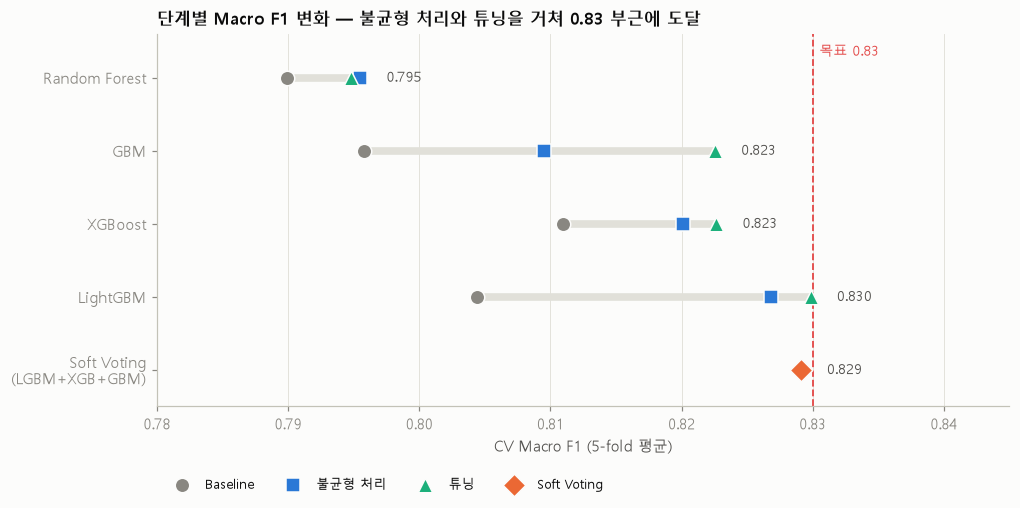

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.4))
names = ["Random Forest", "GBM", "XGBoost", "LightGBM"]
stages = [("Baseline", MUTED, "o"), ("불균형 처리", BLUE, "s"), ("튜닝", AQUA, "^")]
for i, n in enumerate(names):
    vals = [base.loc[n, "macro_f1_mean"], prev.loc[n, "불균형 처리 후 Macro F1"], tsum.loc[n, "macro_f1_mean"]]
    ax.plot(vals, [i] * 3, color=GRID, lw=5, solid_capstyle="round", zorder=1)
    for (lab, c, mk), v in zip(stages, vals):
        ax.scatter(v, i, s=90, color=c, marker=mk, edgecolor=SURFACE, lw=1, zorder=3, label=lab if i == 0 else None)
    ax.text(max(vals) + 0.002, i, f"{vals[-1]:.3f}", va="center", fontsize=9, color=INK2)
vv = tsum.loc["Soft Voting (LGBM+XGB+GBM)", "macro_f1_mean"]
ax.scatter(vv, len(names), s=110, color=ORANGE, marker="D", edgecolor=SURFACE, lw=1, zorder=3, label="Soft Voting")
ax.text(vv + 0.002, len(names), f"{vv:.3f}", va="center", fontsize=9, color=INK2)
ax.axvline(0.83, color=RED, lw=1.2, ls="--"); ax.text(0.8305, -0.3, "목표 0.83", color=RED, fontsize=9)
ax.set_yticks(range(len(names) + 1), names + ["Soft Voting\n(LGBM+XGB+GBM)"]); ax.invert_yaxis(); ax.set_ylim(len(names) + 0.5, -0.6)
ax.set_xlabel("CV Macro F1 (5-fold 평균)"); ax.grid(axis="y", visible=False); ax.set_xlim(0.78, 0.845)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.16), ncol=4, frameon=False, fontsize=8.5)
ax.set_title("단계별 Macro F1 변화 — 불균형 처리와 튜닝을 거쳐 0.83 부근에 도달")
save(fig, "Taegyeom_tuning_stage_progress.png")

## 7. 클래스별 성능과 오분류 변화 (OOF)

In [11]:
base_oof = pd.read_csv(PROJECT_ROOT / "results/baseline/Taegyeom_baseline_oof_predictions.csv", index_col=0)
comp = {"Baseline XGBoost": base_oof["XGBoost"], "Baseline LightGBM": base_oof["LightGBM"],
        "튜닝 LightGBM": tuned["LightGBM"]["oof"], "Soft Voting": tuned["Soft Voting (LGBM+XGB+GBM)"]["oof"]}
pc = pd.concat({k: per_class_report(y_train, v) for k, v in comp.items()}, names=["model", "class"])
pc.to_csv(RESULT_DIR / "Taegyeom_tuning_per_class_oof.csv")
for metric in ["recall", "precision", "f1"]:
    t = pc[metric].unstack("class")[CLASS_ORDER]; t["macro"] = t.mean(axis=1)
    print(f"[{metric.upper()}]"); display(t.round(3))
ke = pd.DataFrame({k: key_error_counts(y_train, v) for k, v in comp.items()}).T
ke.to_csv(RESULT_DIR / "Taegyeom_tuning_key_errors_oof.csv")
print("[주요 오분류 건수 (OOF, Train 1,552건)]"); ke

[RECALL]


class,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness,macro
model,,,,,,,,
Baseline XGBoost,0.771,0.682,0.965,0.947,0.508,0.931,0.795,0.800
Baseline LightGBM,0.764,0.682,0.958,0.928,0.524,0.931,0.773,0.794
튜닝 LightGBM,0.729,0.732,0.968,0.941,0.675,0.966,0.795,0.829
Soft Voting,0.719,0.732,0.965,0.947,0.667,0.931,0.841,0.829


[PRECISION]


class,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness,macro
model,,,,,,,,
Baseline XGBoost,0.733,0.670,0.971,0.954,0.627,0.947,0.921,0.832
Baseline LightGBM,0.726,0.672,0.965,0.928,0.653,0.947,0.872,0.823
튜닝 LightGBM,0.775,0.664,0.971,0.929,0.664,0.949,0.897,0.836
Soft Voting,0.769,0.666,0.974,0.923,0.636,0.931,0.925,0.832


[F1]


class,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness,macro
model,,,,,,,,
Baseline XGBoost,0.752,0.676,0.968,0.950,0.561,0.939,0.854,0.814
Baseline LightGBM,0.745,0.677,0.962,0.928,0.581,0.939,0.819,0.807
튜닝 LightGBM,0.751,0.696,0.970,0.935,0.669,0.957,0.843,0.832
Soft Voting,0.744,0.697,0.970,0.935,0.651,0.931,0.881,0.830


[주요 오분류 건수 (OOF, Train 1,552건)]


,소수 유형 → Other_Faults·Bumps,Other_Faults → 소수 유형 (오경보),Bumps ↔ Other_Faults,K_Scratch ↔ Z_Scratch,전체 오분류
Baseline XGBoost,71,26,172,1,319
Baseline LightGBM,69,24,171,0,327
튜닝 LightGBM,48,32,169,1,303
Soft Voting,49,37,169,1,309


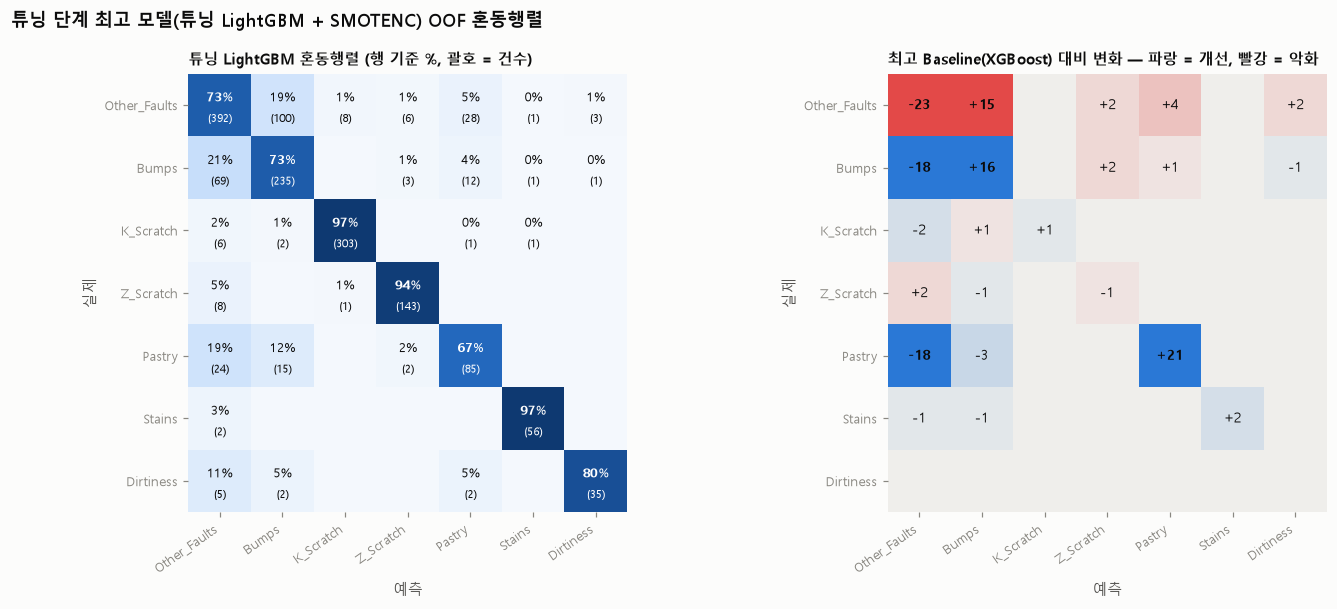

In [12]:
final_key = "LightGBM"   # 8번에서 튜닝 단계 최고 모델로 선정
cb_, ca_ = confusion_df(y_train, base_oof["XGBoost"]), confusion_df(y_train, tuned[final_key]["oof"])
diff = ca_ - cb_
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
pct = ca_.div(ca_.sum(axis=1), axis=0) * 100
axes[0].imshow(pct.values, cmap=SEQ, vmin=0, vmax=100)
for i in range(7):
    for j in range(7):
        if ca_.values[i, j]:
            col = "white" if pct.values[i, j] > 55 else INK
            axes[0].text(j, i - 0.12, f"{pct.values[i, j]:.0f}%", ha="center", va="center", fontsize=8.5, color=col, fontweight="bold" if i == j else None)
            axes[0].text(j, i + 0.22, f"({ca_.values[i, j]})", ha="center", va="center", fontsize=7, color=col)
v = diff.values.astype(float); good = np.where(np.eye(7, dtype=bool), v, -v)
axes[1].imshow(good, cmap=DIV, norm=TwoSlopeNorm(vmin=-15, vcenter=0, vmax=15))
for i in range(7):
    for j in range(7):
        if v[i, j]: axes[1].text(j, i, f"{int(v[i, j]):+d}", ha="center", va="center", fontsize=9, color=INK, fontweight="bold" if abs(v[i, j]) >= 8 else None)
for ax, ttl in [(axes[0], "튜닝 LightGBM 혼동행렬 (행 기준 %, 괄호 = 건수)"), (axes[1], "최고 Baseline(XGBoost) 대비 변화 — 파랑 = 개선, 빨강 = 악화")]:
    ax.set_xticks(range(7), CLASS_ORDER, rotation=35, ha="right", fontsize=8.5); ax.set_yticks(range(7), CLASS_ORDER, fontsize=8.5)
    ax.set_xlabel("예측"); ax.set_ylabel("실제"); ax.grid(False); ax.set_title(ttl, fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("튜닝 단계 최고 모델(튜닝 LightGBM + SMOTENC) OOF 혼동행렬", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_tuning_confusion_best_model.png")
diff.to_csv(RESULT_DIR / "Taegyeom_tuning_confusion_diff_vs_baseline.csv")

**해석 — 클래스별 변화 (튜닝 LightGBM vs Baseline LightGBM, OOF)**
- **Pastry(최대 병목)**: Recall 0.52 → **0.68**, Precision 0.65 → 0.66으로 **정밀도를 잃지 않고 재현율이 오름** → F1 0.58 → **0.67**
- **Bumps**: Recall 0.68 → 0.73, F1 0.68 → 0.70 / **Stains** F1 0.94 → 0.96 / **Dirtiness** F1 0.82 → 0.84
- **대가 — Other_Faults Recall 0.76 → 0.73**: 실제 Other_Faults가 Bumps·Pastry로 넘어가는 경우가 늘었습니다. 대신 Other_Faults Precision이 0.73 → 0.78로 올라 F1은 0.745 → 0.751로 유지됩니다.
- **오분류 건수 (Baseline LightGBM → 튜닝 LightGBM)**: 놓침(소수 → Other·Bumps) 69 → **48건(−21)**, 오경보(Other → 소수) 24 → **32건(+8)**, 전체 오분류 327 → **303건(−24)**
  → 놓침 감소가 오경보 증가보다 커서, 문제 정의에서 정한 우선순위(놓침을 더 중요하게)에 맞는 변화입니다.
- **혼동행렬(최고 Baseline XGBoost 대비)**: Pastry 정답 +21건(Pastry → Other_Faults −18건), Bumps 정답 +16건. 반면 실제 Other_Faults → Bumps가 +15건 늘어 **Bumps ↔ Other_Faults 혼동(169건)은 여전히 최대 오류원**입니다.

## 8. 튜닝 단계 최고 모델 선정

In [13]:
sel = pd.DataFrame({
    "5-fold Macro F1": tsum.loc[rep_keys, "macro_f1_mean"].round(4),
    "5-fold std": tsum.loc[rep_keys, "macro_f1_std"].round(4),
    "반복 CV(5×3) 평균": rep_tbl.loc[rep_keys, "평균"].astype(float).round(4),
    "0.83 이상 fold": rep_tbl.loc[rep_keys, "0.83 이상 fold 수"],
    "Train-Val 차이": tsum.loc[rep_keys, "overfit_gap"].round(3),
    "놓침/오경보": [f"{key_error_counts(y_train, tuned[k]['oof']).iloc[0]} / {key_error_counts(y_train, tuned[k]['oof']).iloc[1]}" for k in rep_keys],
    "학습 시간(초/fold)": tsum.loc[rep_keys, "fit_time_sec"].round(1),
})
sel.to_csv(RESULT_DIR / "Taegyeom_tuning_final_selection.csv")

# 튜닝 단계 최고 모델 설정 저장 (최종 평가 노트북에서 Train 전체로 재학습 후 Test 1회 평가에 사용)
final_cfg = {"model": "LightGBM", "sampler": "SMOTENC IR=1 (k_neighbors=5)", "params": clean(best_params["LightGBM"]),
             "cv_macro_f1_5fold": round(float(tsum.loc["LightGBM", "macro_f1_mean"]), 4),
             "cv_macro_f1_repeated_5x3": round(float(rep_tbl.loc["LightGBM", "평균"]), 4)}
json.dump(final_cfg, open(RESULT_DIR / "Taegyeom_tuning_best_config.json", "w"), ensure_ascii=False, indent=2, default=str)
sel

,5-fold Macro F1,5-fold std,반복 CV(5×3) 평균,0.83 이상 fold,Train-Val 차이,놓침/오경보,학습 시간(초/fold)
LightGBM,0.8298,0.0183,0.8260,8/15,0.170,48 / 32,10.7
XGBoost,0.8226,0.0230,0.8211,6/15,0.177,48 / 39,1.4
GBM,0.8225,0.0182,0.8207,4/15,0.175,48 / 40,9.3
Soft Voting (LGBM+XGB+GBM),0.8291,0.0114,0.8265,7/15,0.171,49 / 37,19.5


**튜닝 단계 최고 모델: 튜닝 LightGBM + SMOTENC 균등화**

| 판단 기준 | 튜닝 LightGBM | Soft Voting (LGBM+XGB+GBM) |
|---|---|---|
| 5-fold Macro F1 | **0.830** ± 0.018 | 0.829 ± 0.011 |
| 반복 CV(5×3) 평균 | 0.826 | 0.827 |
| 놓침 / 오경보 / 전체 오분류 (OOF) | **48 / 32 / 303** | 49 / 37 / 309 |
| Pastry F1 / Dirtiness F1 | **0.669** / 0.843 | 0.651 / **0.881** |
| 학습 시간(fold당) | **약 11초** | 약 20초 (모델 3개) |
| 해석 가능성 | 단일 모델 → Feature Importance·SHAP 해석 용이 | 3개 모델 결합 → 해석 복잡 |

- 두 후보의 Macro F1 차이(0.001)는 fold 편차(±0.01~0.02)보다 훨씬 작아 **성능상 동률**입니다. 동률이면 **오경보가 적고(32 vs 37), 전체 오분류가 적으며, 단순하고 해석 가능한** 튜닝 LightGBM을 선택합니다.
  Soft Voting은 fold 간 편차가 작고 Dirtiness가 더 좋아 **대안 후보**로 기록합니다.
- **목표 0.83 달성 여부**: 5-fold 기준 0.830으로 목표선에 도달했지만, 반복 CV 평균은 0.826이고 15개 fold 중 8개만 0.83 이상입니다.
  **"평균적으로 목표에 근접, 안정적으로 넘는다고 보기는 어려움"** 이 정직한 결론입니다. 또한 탐색에 사용한 fold로 최고 조합을 고른 점수는 약간 낙관적일 수 있습니다(반복 CV 0.826이 더 현실적인 추정).
- **Baseline 대비 개선 요약**: 최고 Baseline(XGBoost 0.811) → 튜닝 LightGBM 0.830(+0.019), LightGBM 기준으로는 0.804 → 0.830(+0.026). 그중 약 0.022는 불균형 처리(SMOTENC), 약 0.003은 하이퍼파라미터 튜닝에서 왔습니다.
- **다음 단계**: 이 설정(`results/tuning/Taegyeom_tuning_best_config.json`)으로 Train 전체를 학습한 뒤 **Test 389건으로 최종 평가를 1회** 수행합니다.
  추가 개선 여지는 Bumps ↔ Other_Faults 경계를 직접 다루는 Feature Engineering과 클래스별 Threshold 조정입니다.